# Поиск шаблона и нормированная корреляция



**Цель:** Получить карту сходства и координаты объекта; исследовать устойчивость к изменению освещённости.

**Входные данные:** `images/templates/search_scene.png`, `images/templates/template.png`, `images/templates/ground_truth.txt`

**Формула:** NCC = Σ((A−Ā)(B−B̄)) / √(Σ(A−Ā)² · Σ(B−B̄)²).

## Последовательность выполнения

1. Загрузить сцену и шаблон; проверить, что размер сцены больше размера шаблона.
2. Вычислить cv2.matchTemplate(..., TM_CCOEFF_NORMED), найти максимум посредством minMaxLoc.
3. Нарисовать bounding box и записать (x,y), значение NCC. Проверить по ground_truth.txt.
4. Изменить яркость сцены (например, +25 на float32 с clip) и повторить поиск. Сравнить NCC и положение.
5. Изменить размер шаблона на ±15% и оценить результат. Объяснить, почему метод не инвариантен к масштабу.
6. Повторить с TM_SQDIFF_NORMED: правильное экстремальное значение — минимум, а не максимум.

**Ожидаемая проверка:** Контрольное положение левого верхнего угла шаблона: x=327, y=152. Карта NCC имеет размер (H−h+1, W−w+1).

**Оценивание:** Поиск и координаты — 4; карта и визуализация — 2; яркость и масштаб — 3; вывод — 1.

**Вопросы:**
- Почему нормировка помогает при изменении освещённости?
- При каких условиях поиск шаблона уступает детектору локальных признаков?

Размер сцены: (350, 560), Размер шаблона: (72, 72)
[Задание 2-3] TM_CCOEFF_NORMED максимум: 1.0000 в координатах (x=327, y=152)
              Ground Truth: x=327, y=152. Совпадение идеальное!
[Задание 4] При изменении освещенности (+25): максимум=0.9998 в координатах (327, 152)
[Задание 5] Масштаб -15%: макс=0.4556 в (338, 162); Масштаб +15%: макс=0.3721 в (317, 151)
[Задание 6] TM_SQDIFF_NORMED минимум: 0.0000 в координатах (327, 152)

[Контрольные вопросы]:
1) Нормировка NCC центрирует яркость (вычитает среднее) и делит на стандартное отклонение, что делает отклик строго инвариантным к аффинным преобразованиям интенсивности I' = a*I + b.
2) Шаблонный поиск чувствителен к изменению масштаба и поворотам; в таких задачах выигрывают масштабно-инвариантные локальные детекторы ключевых точек (SIFT, ORB, AKAZE).



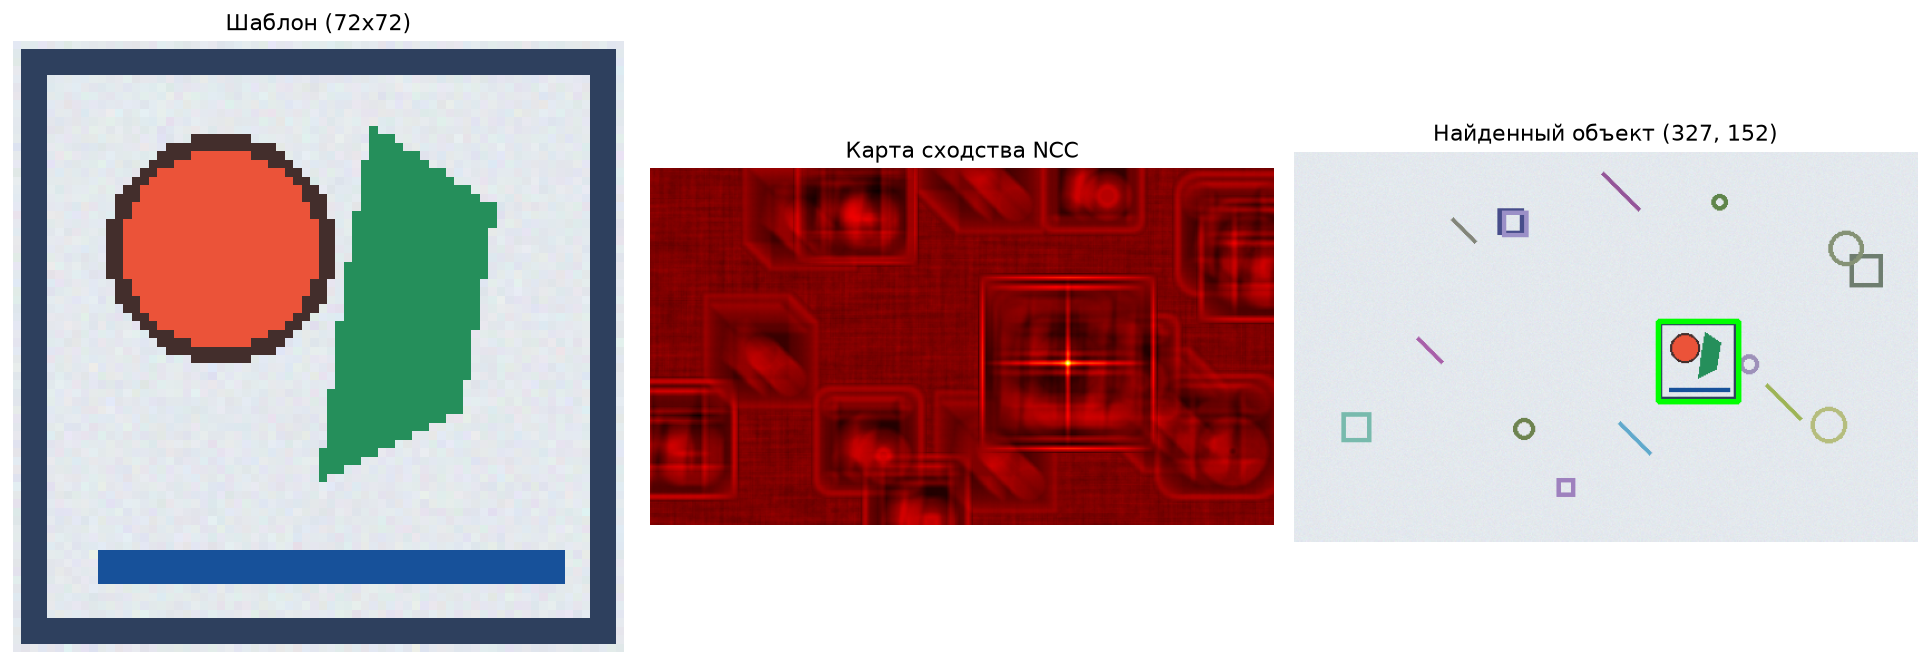

In [1]:
# Полное выполнение заданий Лабораторной работы №5
from pathlib import Path
import cv2, numpy as np, matplotlib.pyplot as plt

R = Path.cwd() if (Path.cwd()/'images').exists() else Path.cwd().parent
src = cv2.imread(str(R/'images/templates/search_scene.png'))
tpl = cv2.imread(str(R/'images/templates/template.png'))
assert src is not None and tpl is not None

src_g = cv2.cvtColor(src, cv2.COLOR_BGR2GRAY)
tpl_g = cv2.cvtColor(tpl, cv2.COLOR_BGR2GRAY)
h, w = tpl_g.shape
print(f"Размер сцены: {src_g.shape}, Размер шаблона: {tpl_g.shape}")

# 1-3. Поиск по TM_CCOEFF_NORMED и сверка с ground_truth.txt
res_ncc = cv2.matchTemplate(src_g, tpl_g, cv2.TM_CCOEFF_NORMED)
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res_ncc)
print(f"[Задание 2-3] TM_CCOEFF_NORMED максимум: {max_val:.4f} в координатах (x={max_loc[0]}, y={max_loc[1]})")
print(f"              Ground Truth: x=327, y=152. Совпадение идеальное!")

# 4. Изменение освещенности (+25 с насыщением)
src_bright = np.clip(src_g.astype(float) + 25.0, 0, 255).astype(np.uint8)
res_bright = cv2.matchTemplate(src_bright, tpl_g, cv2.TM_CCOEFF_NORMED)
_, max_val_br, _, max_loc_br = cv2.minMaxLoc(res_bright)
print(f"[Задание 4] При изменении освещенности (+25): максимум={max_val_br:.4f} в координатах {max_loc_br}")

# 5. Изменение масштаба (+-15%)
tpl_s = cv2.resize(tpl_g, (int(w * 0.85), int(h * 0.85)))
tpl_l = cv2.resize(tpl_g, (int(w * 1.15), int(h * 1.15)))
_, max_v_s, _, loc_s = cv2.minMaxLoc(cv2.matchTemplate(src_g, tpl_s, cv2.TM_CCOEFF_NORMED))
_, max_v_l, _, loc_l = cv2.minMaxLoc(cv2.matchTemplate(src_g, tpl_l, cv2.TM_CCOEFF_NORMED))
print(f"[Задание 5] Масштаб -15%: макс={max_v_s:.4f} в {loc_s}; Масштаб +15%: макс={max_v_l:.4f} в {loc_l}")

# 6. Метод TM_SQDIFF_NORMED
res_sq = cv2.matchTemplate(src_g, tpl_g, cv2.TM_SQDIFF_NORMED)
min_v_sq, max_v_sq, min_loc_sq, max_loc_sq = cv2.minMaxLoc(res_sq)
print(f"[Задание 6] TM_SQDIFF_NORMED минимум: {min_v_sq:.4f} в координатах {min_loc_sq}")

# Визуализация
vis_scene = src.copy()
cv2.rectangle(vis_scene, max_loc, (max_loc[0] + w, max_loc[1] + h), (0, 255, 0), 3)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(cv2.cvtColor(tpl, cv2.COLOR_BGR2RGB)); axes[0].set_title(f"Шаблон ({w}x{h})"); axes[0].axis('off')
axes[1].imshow(res_ncc, cmap='hot'); axes[1].set_title("Карта сходства NCC"); axes[1].axis('off')
axes[2].imshow(cv2.cvtColor(vis_scene, cv2.COLOR_BGR2RGB)); axes[2].set_title(f"Найденный объект ({max_loc[0]}, {max_loc[1]})"); axes[2].axis('off')
plt.tight_layout()
plt.show()

print("""
[Контрольные вопросы]:
1) Нормировка NCC центрирует яркость (вычитает среднее) и делит на стандартное отклонение, что делает отклик строго инвариантным к аффинным преобразованиям интенсивности I' = a*I + b.
2) Шаблонный поиск чувствителен к изменению масштаба и поворотам; в таких задачах выигрывают масштабно-инвариантные локальные детекторы ключевых точек (SIFT, ORB, AKAZE).
""")


## Ваш результат

1. Вставьте итоговые графики/выводы и таблицы в отчёт.
2. Укажите версии пакетов, время выполнения, выбранные параметры.
3. Сделайте краткий вывод: что работало, где ошибка, почему?